# GOES ABI area query

Satellite **pictures of the clouds** and calibrated **cloud products** for a circle of radius `RADIUS_KM` around a lat/lon, over a UTC time range. Everything is read straight from NOAA's public AWS buckets (`noaa-goes18` = GOES-West, `noaa-goes19` = GOES-East), the same ABI files CIRA SLIDER shows.

1. **Satellite images:** RGB composites such as true colour, cloud phase and IR clouds, one picture per scan (every 5 min on CONUS/PACUS). They are drawn north-up around your point with the circle marked, and saved as PNGs plus an animated GIF.
2. **Cloud products (numbers):** cloud mask, cloud-top height, phase and so on, on the native ABI pixel grid inside the circle. They are saved as NetCDF, with a CSV of per-scan statistics such as cloud fraction.

Every frame carries its exact scan start (`time`) and end (`time_end`) in UTC. Logic lives in [src/goes_query.py](src/goes_query.py). **Kernel:** the `mapping` conda env.

In [26]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
sys.path.insert(0, str(Path("src").resolve()))
import goes_query as gq

pd.set_option("display.max_colwidth", 90)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Settings

* **Satellite**: `goes18` = GOES-West (137.2°W), `goes19` = GOES-East (75.2°W). Use whichever sees your point at the lower view angle.
* **Sector**: `"C"` = CONUS/PACUS every 5 min. `"F"` = full disk every 10 min. `"M1"`/`"M2"` = 1-min mesoscale boxes, which move around.
* **Daylight**: visible composites (`true_color`, `cloud_phase`, …) are black at night. Use `colorized_ir_clouds`, `C13` or `night_microphysics` then.

In [30]:
LAT, LON   = 52.82457466754165, -110.88594474303841      # centre (deg)  <-- set your site
RADIUS_KM  = 14                   # analysis circle; 14 km radius ≈ 600 km²

START = "2026-10-17 20:00"        # UTC   (08:30 PDT)
END   = "2026-10-17 22:00"        # UTC, inclusive (scan start time)

SATELLITE = "goes18"
SECTOR    = "F"
MODE      = "stream"              # or "download" to cache raw files in data/raw/

# --- satellite images ---
IMAGES  = ["true_color", "colorized_ir_clouds"]   # see the composites table below
VIEW_KM = 60                      # half-width of each picture (the circle is drawn inside)

# --- cloud products (numbers) ---
PRODUCTS = ["cloud_mask", "cloud_top_height", "cloud_top_phase"]
DATASETS = {"imagery": ["C02", "C07", "C13"]}   # optional per-product variable overrides

OUT_DIR = "output"

# 1. Satellite images

Available composites (any other satpy composite name, or a single channel such as `C02`/`C13`, also works):

In [31]:
gq.composites_table()

,channels,description
composite,,
true_color,C01 C02 C03,"Day: what the eye sees, Rayleigh-corrected, 0.5 km"
natural_color,C02 C03 C05,"Day: water clouds white, ice clouds/snow cyan"
cloud_phase,C02 C05 C06,Day: liquid (white/yellow) vs ice (green/blue) tops
day_cloud_type,C02 C04 C05,"Day: cloud type (cirrus, low, thick ice)"
day_microphysics_abi,C03 C06 C13,Day: cloud particle size / phase
colorized_ir_clouds,C13,"Day & night: 10.3 µm IR, cold tops coloured"
C13,C13,"Day & night: 10.3 µm clean IR window, greyscale"
C02,C02,"Day: 0.64 µm red visible, 0.5 km, greyscale"
night_microphysics,C07 C13 C15,Night: low cloud and fog


In [32]:
images = {}
for comp in IMAGES:
    print(f"--- {comp}")
    images[comp] = gq.fetch_images(LAT, LON, START, END, comp, view_km=VIEW_KM, radius_km=RADIUS_KM,
                                   sector=SECTOR, satellite=SATELLITE, mode=MODE, workers=4)
    print(f"{images[comp].sizes['time']} scans, {images[comp].sizes['x']}×{images[comp].sizes['y']} px")

--- true_color


  0%|          | 0/12 [00:00<?, ?scan/s]

12 scans, 240×240 px
--- colorized_ir_clouds


  0%|          | 0/12 [00:00<?, ?scan/s]

12 scans, 60×60 px


Latest scan of each composite. Pass `t=` an index or a timestamp to pick another.

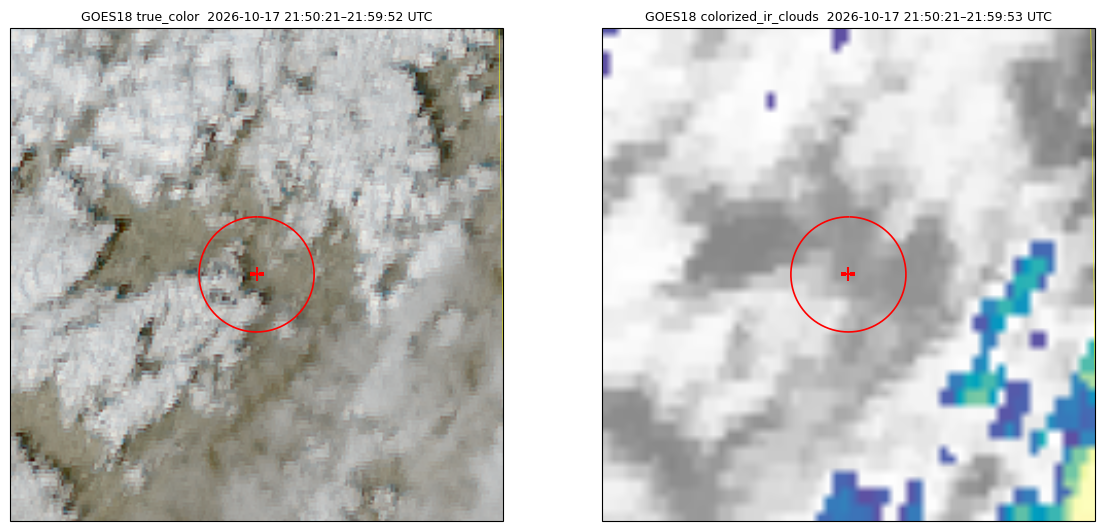

In [33]:
fig, axes = plt.subplots(1, len(images), figsize=(7 * len(images), 7), squeeze=False,
                         subplot_kw={"projection": gq._image_projection(next(iter(images.values())))})
for ax, img in zip(axes.flat, images.values()):
    gq.plot_image(img, t=-1, ax=ax)
plt.show()

Evolution over the time range:

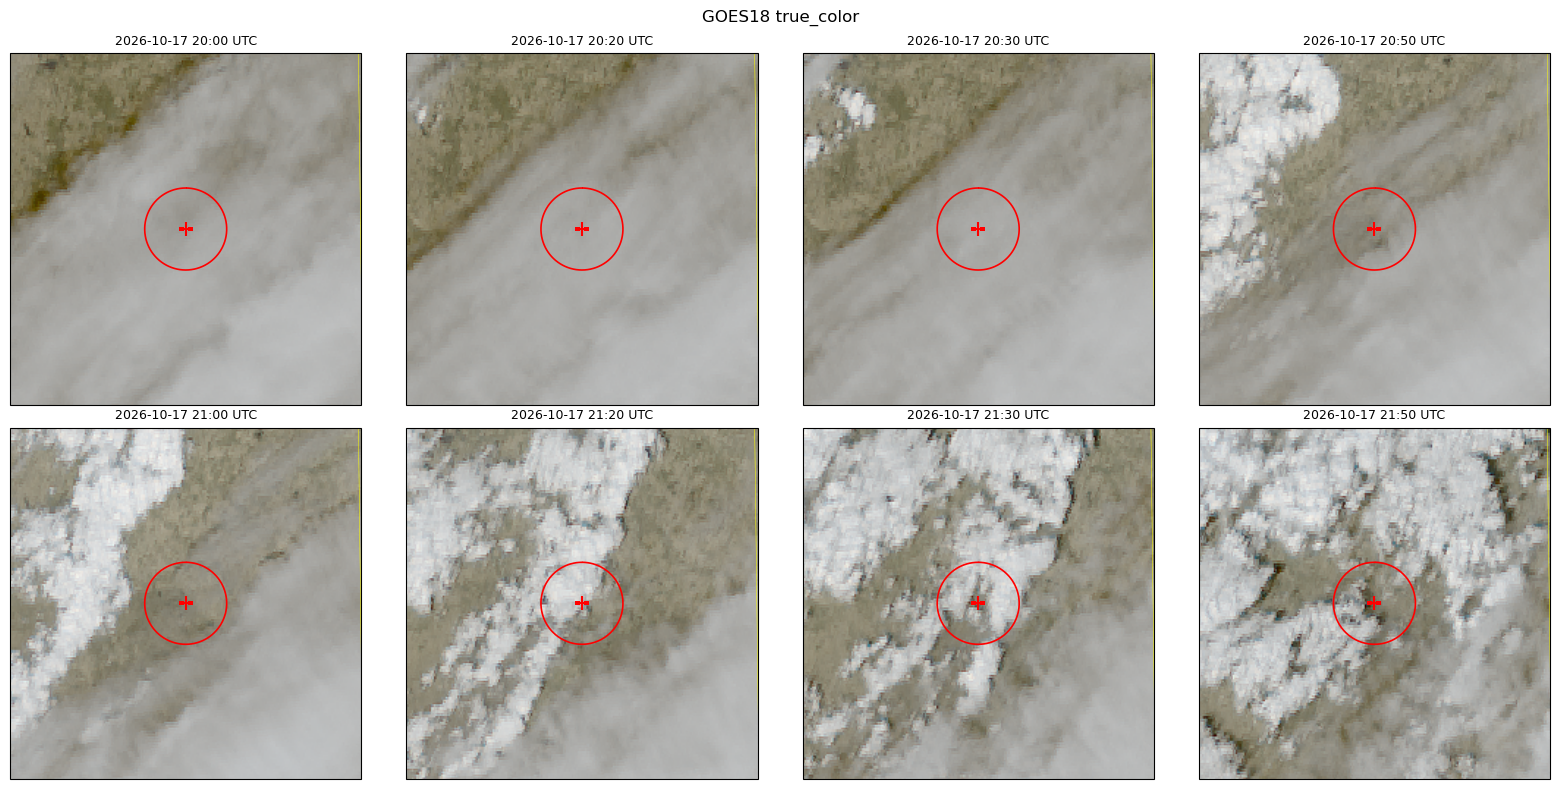

In [34]:
gq.plot_images(images[IMAGES[0]], n=8)
plt.show()

Save one annotated PNG per scan (named by scan start, UTC) plus `animation.gif`:

In [35]:
for comp, img in images.items():
    print(comp, "→", gq.save_images(img, f"{OUT_DIR}/images"))

true_color → output/images/goes18_true_color_F_52.825_-110.886_v60km
colorized_ir_clouds → output/images/goes18_colorized_ir_clouds_F_52.825_-110.886_v60km


# 2. Cloud products (numbers inside the circle)

Values stay on the **native ABI fixed grid**. Each scan is cropped around your point and nothing is interpolated. The output has 2-D `lat`/`lon`, `distance_km` and an `in_radius` mask.

In [36]:
gq.catalog_table()

,bucket_folder,variables,sectors,res_km,description
product,,,,,
cloud_mask,ABI-L2-ACM{C|F|M},"BCM, ACM, Cloud_Probabilities",CFM,2,"Clear-sky mask: BCM binary cloud mask, ACM 4-level mask, cloud probability"
cloud_top_height,ABI-L2-ACHA2KM{C|F|M},HT,CFM,2,"Cloud-top height [m], 2 km"
cloud_top_height_10km,ABI-L2-ACHA{C|F|M},HT,CFM,10,"Cloud-top height [m], 10 km"
cloud_top_temperature,ABI-L2-ACHT{C|F|M},TEMP,FM,2,Cloud-top temperature [K]
cloud_top_phase,ABI-L2-ACTP{C|F|M},Phase,CFM,2,Cloud-top phase: clear / liquid / supercooled / mixed / ice
cloud_top_pressure,ABI-L2-CTP{C|F|M},PRES,CF,10,"Cloud-top pressure [hPa], 10 km"
cloud_optical_depth,ABI-L2-COD{C|F|M},COD,CF,2,"Cloud optical depth (C: 2 km, F: 4 km)"
cloud_particle_size,ABI-L2-CPS{C|F|M},CPS,CFM,2,Cloud particle effective radius [um]
imagery,ABI-L2-CMIP{C|F|M},"C02, C13",CFM,0.5-2,Cloud & Moisture Imagery: reflectance (C01-06) / brightness temp K (C07-16)


Preview what will be read. `size_mb` is the full file size; in `stream` mode only a small fraction of that is transferred.

In [37]:
for prod in PRODUCTS:
    files = gq.list_files(prod, START, END, sector=SECTOR, satellite=SATELLITE, datasets=DATASETS.get(prod))
    print(f"{prod:28s} {files.start_time.nunique():4d} scans  {len(files):4d} files  "
          f"{files.size_mb.sum():8.1f} MB full-file size")

cloud_mask                     12 scans    12 files     284.9 MB full-file size
cloud_top_height               12 scans    12 files     367.0 MB full-file size
cloud_top_phase                12 scans    12 files      42.9 MB full-file size


Optional: list the variables actually inside a product's files.

In [38]:
gq.inspect_product("cloud_mask", START, sector=SECTOR, satellite=SATELLITE)

noaa-goes18/ABI-L2-ACMF/2026/290/19/OR_ABI-L2-ACMF-M6_G18_s20262901930213_e20262901939522_c20262901940152.nc


,shape,units,long_name
variable,,,
BCM,"(5424, 5424)",1,ABI L2+ Clear Sky Mask
ACM,"(5424, 5424)",,(Real-Value) four level cloud mask
Cloud_Probabilities,"(5424, 5424)",,ABI Cloud Mask product Cloud Probabilities
DQF,"(5424, 5424)",1,ABI L2+ Clear Sky Mask data quality flags


In [39]:
results = {}
for prod in PRODUCTS:
    print(f"--- {prod}")
    results[prod] = gq.fetch(prod, LAT, LON, RADIUS_KM, START, END,
                             sector=SECTOR, satellite=SATELLITE, mode=MODE,
                             datasets=DATASETS.get(prod), workers=4)

ds = results[PRODUCTS[0]]
ds

--- cloud_mask


  0%|          | 0/12 [00:00<?, ?scan/s]

--- cloud_top_height


  0%|          | 0/12 [00:00<?, ?scan/s]

--- cloud_top_phase


  0%|          | 0/12 [00:00<?, ?scan/s]

<xarray.Dataset> Size: 33kB
Dimensions:              (time: 12, y: 10, x: 21)
Coordinates:
  * time                 (time) datetime64[us] 96B 2026-10-17T20:00:21.300000...
    time_end             (time) datetime64[us] 96B 2026-10-17T20:09:52.200000...
  * y                    (y) float64 80B 4.66e+06 4.658e+06 ... 4.642e+06
  * x                    (x) float64 168B 1.538e+06 1.54e+06 ... 1.578e+06
    lat                  (y, x) float32 840B 52.97 52.97 52.98 ... 52.65 52.66
    lon                  (y, x) float32 840B -111.1 -111.1 ... -110.7 -110.6
    distance_km          (y, x) float32 840B 23.82 22.19 20.76 ... 23.82 25.25
    in_radius            (y, x) bool 210B False False False ... False False
Data variables:
    BCM                  (time, y, x) float32 10kB nan nan nan ... nan nan nan
    ACM                  (time, y, x) float32 10kB nan nan nan ... nan nan nan
    Cloud_Probabilities  (time, y, x) float32 10kB nan nan nan ... nan nan nan
Attributes: (12/13)
    crs_wkt:         PROJCRS["unknown",BASEGEOGCRS["unknown",DATUM["Unknown b...
    product:         ABI-L2-ACMF
    product_key:     cloud_mask
    satellite:       noaa-goes18
    center_lat:      52.82457466754165
    center_lon:      -110.88594474303841
    ...              ...
    query_start:     2026-10-17 20:00:00
    query_end:       2026-10-17 22:00:00
    sector:          F
    source:          s3://noaa-goes18/ABI-L2-ACMF
    time_note:       time = scan start, time_end = scan end (UTC), from the f...
    n_scans_failed:  0

Save (NetCDF cube + per-scan summary CSV):

In [40]:
for prod, d in results.items():
    print(prod, gq.save(d, OUT_DIR))

cloud_mask {'netcdf': PosixPath('output/goes18_cloud_mask_F_52.825_-110.886_r14km_20261017T2000-20261017T2150.nc'), 'summary_csv': PosixPath('output/goes18_cloud_mask_F_52.825_-110.886_r14km_20261017T2000-20261017T2150_summary.csv')}
cloud_top_height {'netcdf': PosixPath('output/goes18_cloud_top_height_F_52.825_-110.886_r14km_20261017T2000-20261017T2150.nc'), 'summary_csv': PosixPath('output/goes18_cloud_top_height_F_52.825_-110.886_r14km_20261017T2000-20261017T2150_summary.csv')}
cloud_top_phase {'netcdf': PosixPath('output/goes18_cloud_top_phase_F_52.825_-110.886_r14km_20261017T2000-20261017T2150.nc'), 'summary_csv': PosixPath('output/goes18_cloud_top_phase_F_52.825_-110.886_r14km_20261017T2000-20261017T2150_summary.csv')}


### Per-scan statistics inside the circle

Flag variables give class fractions, e.g. `BCM:cloudy_or_probably_cloudy` is the cloud fraction. Continuous variables give mean/min/max/std. `*_valid_frac` is the share of in-circle pixels that have a retrieval (cloud-top height only exists where there is cloud).

In [41]:
summaries = {prod: gq.summarize(d) for prod, d in results.items()}
summaries[PRODUCTS[0]].drop(columns="time_end").round(3)

,BCM_valid_frac,BCM:clear_or_probably_clear,BCM:cloudy_or_probably_cloudy,ACM_valid_frac,ACM:clear,ACM:probably_clear,ACM:probably_cloudy,ACM:cloudy,Cloud_Probabilities_valid_frac,Cloud_Probabilities_mean,Cloud_Probabilities_min,Cloud_Probabilities_max,Cloud_Probabilities_std
time,,,,,,,,,,,,,
2026-10-17 20:00:21.300,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.998,0.988,0.999,0.002
2026-10-17 20:10:21.300,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.999,0.992,0.999,0.001
2026-10-17 20:20:21.300,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.997,0.981,0.999,0.004
2026-10-17 20:30:21.300,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.996,0.974,0.999,0.005
2026-10-17 20:40:21.300,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.995,0.947,0.999,0.010
2026-10-17 20:50:21.100,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.999,0.994,0.999,0.001
2026-10-17 21:00:21.100,1.0,0.036,0.964,1.0,0.0,0.036,0.071,0.893,1.0,0.956,0.353,1.000,0.135
2026-10-17 21:10:21.100,1.0,0.089,0.911,1.0,0.0,0.089,0.339,0.571,1.0,0.860,0.120,1.000,0.206
2026-10-17 21:20:21.100,1.0,0.000,1.000,1.0,0.0,0.000,0.018,0.982,1.0,0.998,0.896,1.000,0.014


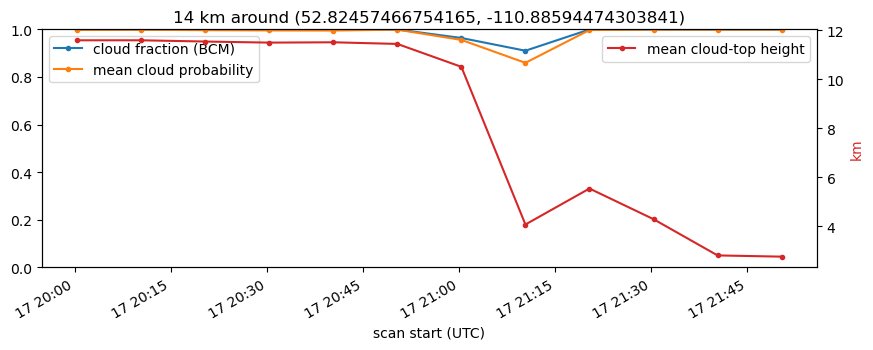

In [42]:
fig, ax = plt.subplots(figsize=(10, 3.5))
s = summaries.get("cloud_mask")
if s is not None:
    s["BCM:cloudy_or_probably_cloudy"].plot(ax=ax, marker=".", label="cloud fraction (BCM)")
    s["Cloud_Probabilities_mean"].plot(ax=ax, marker=".", label="mean cloud probability")
    ax.set_ylim(0, 1)
if "cloud_top_height" in summaries:
    ax2 = ax.twinx()
    (summaries["cloud_top_height"]["HT_mean"] / 1000).plot(ax=ax2, color="tab:red", marker=".", label="mean cloud-top height")
    ax2.set_ylabel("km", color="tab:red")
    ax2.legend(loc="upper right")
ax.set_xlabel("scan start (UTC)")
ax.legend(loc="upper left")
ax.set_title(f"{RADIUS_KM} km around ({LAT}, {LON})")
plt.show()

### Product maps

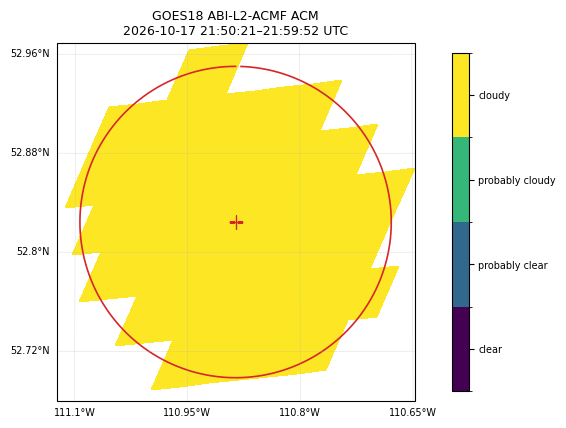

In [43]:
gq.plot_frame(results["cloud_mask"], "ACM", t=-1)
plt.show()

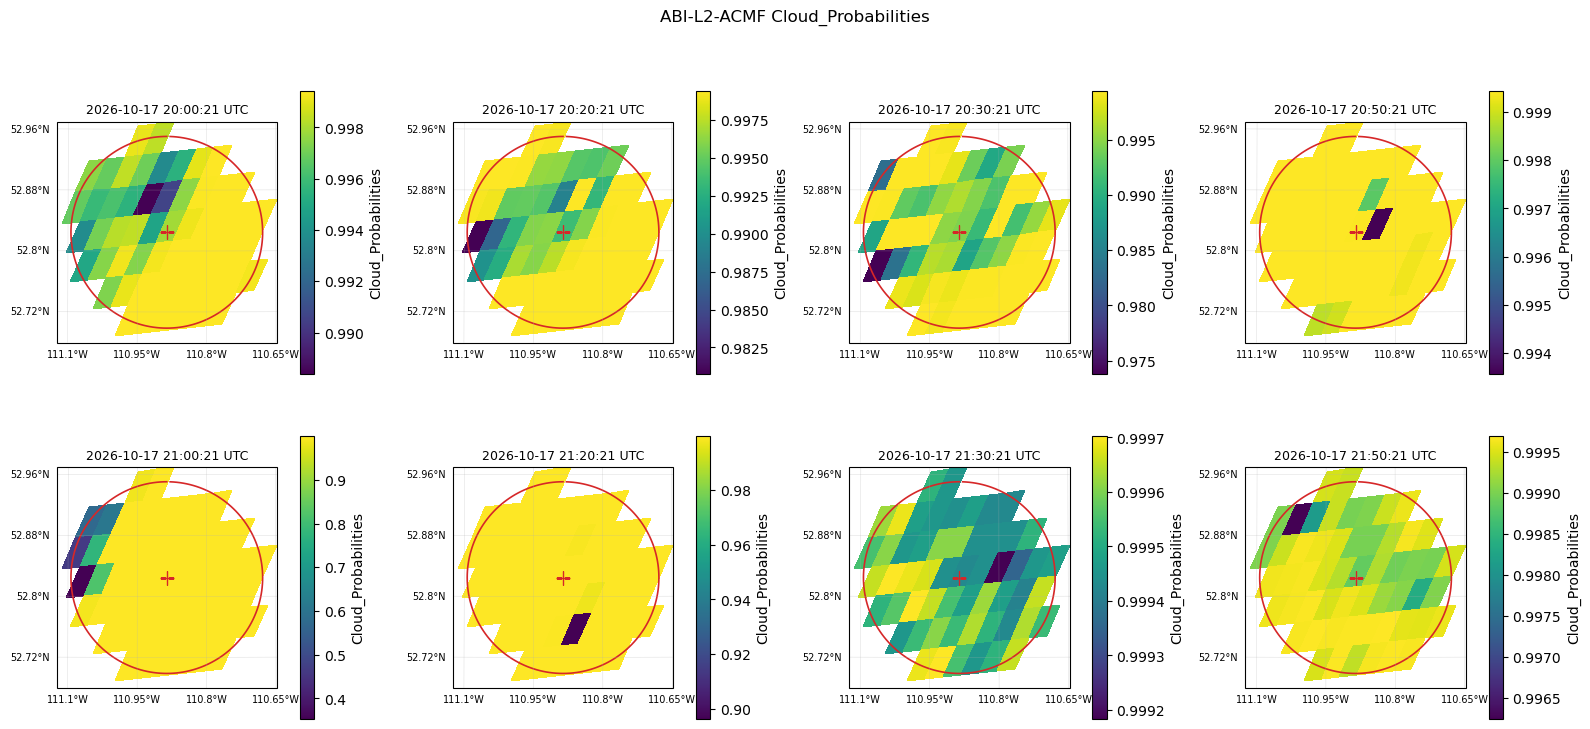

In [44]:
gq.plot_frames(results["cloud_mask"], "Cloud_Probabilities", n=8)
plt.show()

### Pick a single time / the centre pixel

`sel(..., method="nearest")` gets the scan closest to a given moment.

In [45]:
t = pd.Timestamp(START) + (pd.Timestamp(END) - pd.Timestamp(START)) / 2
snap = ds.sel(time=t, method="nearest")
print("nearest scan:", snap.time.values, "→", snap.time_end.values)

iy, ix = np.unravel_index(np.nanargmin(ds.distance_km.values), ds.distance_km.shape)
point = ds.isel(y=iy, x=ix)
print(f"centre pixel at {float(point.lat):.4f}, {float(point.lon):.4f} ({float(point.distance_km):.2f} km from target)")
point.to_dataframe()[list(ds.data_vars)].head()

nearest scan: 2026-10-17T21:00:21.100000 → 2026-10-17T21:09:51.900000
centre pixel at 52.8326, -110.8762 (1.11 km from target)


,BCM,ACM,Cloud_Probabilities
time,,,
2026-10-17 20:00:21.300,1.0,3.0,0.997901
2026-10-17 20:10:21.300,1.0,3.0,0.999275
2026-10-17 20:20:21.300,1.0,3.0,0.993567
2026-10-17 20:30:21.300,1.0,3.0,0.994514
2026-10-17 20:40:21.300,1.0,3.0,0.983037
